# Notebook 03 — Validation & Interpretability

**Project:** RSA Hardness Prediction & PQC Migration Framework
**Phase 3:** SHAP analysis, ablation study, Bland-Altman plots, bootstrap CI

**Key outputs:**
- SHAP global feature importance (regression + classification)
- Per-algorithm feature importance (what drives each algorithm's selection?)
- Ablation study (which base learner contributes most?)
- Bland-Altman agreement analysis
- Bootstrap 95% confidence intervals for R² and accuracy

**Estimated runtime:** ~15–20 minutes

In [1]:
import sys, os
from pathlib import Path

PROJECT_ROOT = Path(os.getcwd()).resolve().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap
import joblib
import warnings
import time

from sklearn.model_selection import train_test_split, KFold
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import ElasticNet
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import (
    r2_score, mean_absolute_error,
    accuracy_score, f1_score,
)
from xgboost import XGBRegressor, XGBClassifier
from catboost import CatBoostRegressor

from src.features import get_feature_names
from src.utils import (
    set_global_seed, print_section, log_memory, save_metadata,
)
from config import (
    SEED, DATA_PROC, DATA_META, MODELS_DIR,
    RESULTS_FIG, RESULTS_TAB,
    SMALL_PRIMES, POWER_MODS,
    TEST_SIZE, N_CV_FOLDS,
    XGBOOST_PARAMS, CATBOOST_PARAMS,
)

warnings.filterwarnings("ignore")
sns.set(style="whitegrid")
set_global_seed(SEED)

print("All imports successful.")

D:\Research\Vulnerability Score assesment - continued\RSA Hardness Framework\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


All imports successful.


## 1. Load Dataset & Retrain Models

We reload the saved dataset and retrain the key models so all variables
are available in this notebook's kernel. This takes ~30 seconds.

In [2]:
print_section("Loading Dataset & Retraining Models")

# Load dataset
df = pd.read_csv(DATA_PROC / "dataset_with_features_and_runtimes.csv")
df = df[df["best_algorithm"] != "none"].reset_index(drop=True)

feature_names = get_feature_names(SMALL_PRIMES, POWER_MODS)
available_features = [f for f in feature_names if f in df.columns]

# Fix dtypes
for col in available_features:
    if df[col].dtype == "object":
        df[col] = pd.to_numeric(df[col], errors="coerce")

# Targets
X = df[available_features].astype(np.float64)
y_reg = df["log_min_runtime"].values
y_cls = df["best_algorithm"].values

label_encoder = LabelEncoder()
y_cls_encoded = label_encoder.fit_transform(y_cls)
class_names = label_encoder.classes_

# Train/test split (same seed = same split as Phase 2)
X_train, X_test, y_reg_train, y_reg_test, y_cls_train, y_cls_test = train_test_split(
    X, y_reg, y_cls_encoded,
    test_size=TEST_SIZE,
    random_state=SEED,
    stratify=y_cls_encoded,
)

print(f"Dataset: {len(df):,} samples, {len(available_features)} features")
print(f"Train: {len(X_train):,} | Test: {len(X_test):,}")

# Retrain XGBoost regressor
print("\nRetraining XGBoost regressor...")
xgb_reg = XGBRegressor(**XGBOOST_PARAMS)
xgb_reg.fit(X_train, y_reg_train, verbose=False)
r2_xgb = r2_score(y_reg_test, xgb_reg.predict(X_test))
print(f"  XGBoost R² = {r2_xgb:.4f}")

# Retrain CatBoost regressor
print("Retraining CatBoost regressor...")
cb_reg = CatBoostRegressor(**CATBOOST_PARAMS)
cb_reg.fit(X_train, y_reg_train, verbose=False)
r2_cb = r2_score(y_reg_test, cb_reg.predict(X_test))
print(f"  CatBoost R² = {r2_cb:.4f}")

# Retrain classifier
print("Retraining XGBoost classifier...")
unique_cls, cls_counts = np.unique(y_cls_train, return_counts=True)
sample_wts = np.array([len(y_cls_train) / (len(unique_cls) * cls_counts[c]) for c in y_cls_train])

xgb_cls = XGBClassifier(
    n_estimators=400, max_depth=6, learning_rate=0.06,
    subsample=0.85, colsample_bytree=0.85,
    tree_method="hist", random_state=SEED, eval_metric="mlogloss",
)
xgb_cls.fit(X_train, y_cls_train, sample_weight=sample_wts, verbose=False)
acc = accuracy_score(y_cls_test, xgb_cls.predict(X_test))
print(f"  Classifier Accuracy = {acc:.4f}")

print("\nAll models ready for analysis.")
log_memory("after retraining")


══════════════════════════════════════════════════════════════════════
  Loading Dataset & Retraining Models
══════════════════════════════════════════════════════════════════════

Dataset: 9,367 samples, 39 features
Train: 7,493 | Test: 1,874

Retraining XGBoost regressor...
  XGBoost R² = 0.5089
Retraining CatBoost regressor...
  CatBoost R² = 0.5411
Retraining XGBoost classifier...
  Classifier Accuracy = 0.7604

All models ready for analysis.
  [MEM] after retraining: 422.6 MB


## 2. SHAP Analysis — Regression Model

SHAP (SHapley Additive exPlanations) reveals which features drive
the model's predictions and by how much.

This produces the most citable finding in the paper:
**"What makes certain semiprimes easier to factor?"**

In [3]:
print_section("SHAP Analysis — XGBoost Regressor")

t0 = time.perf_counter()

# Use TreeExplainer (fast, exact for tree models)
explainer_reg = shap.TreeExplainer(xgb_reg)

# Compute SHAP values on test set
shap_values_reg = explainer_reg.shap_values(X_test)

print(f"SHAP values computed in {time.perf_counter()-t0:.1f}s")
print(f"Shape: {shap_values_reg.shape}")

# Global feature importance (mean absolute SHAP value)
shap_importance = np.abs(shap_values_reg).mean(axis=0)
shap_df = pd.DataFrame({
    "feature": available_features,
    "mean_abs_shap": shap_importance,
}).sort_values("mean_abs_shap", ascending=False)

print(f"\nTop 15 features by SHAP importance (Regression):")
for i, row in shap_df.head(15).iterrows():
    bar = "█" * int(row["mean_abs_shap"] / shap_df["mean_abs_shap"].max() * 30)
    print(f"  {row['feature']:<25s} {row['mean_abs_shap']:>8.4f}  {bar}")

# Save table
shap_df.to_csv(RESULTS_TAB / "shap_regression_importance.csv", index=False)
print(f"\nSaved: {RESULTS_TAB / 'shap_regression_importance.csv'}")


══════════════════════════════════════════════════════════════════════
  SHAP Analysis — XGBoost Regressor
══════════════════════════════════════════════════════════════════════

SHAP values computed in 2.1s
Shape: (1874, 39)

Top 15 features by SHAP importance (Regression):
  log2_N                      1.3091  ██████████████████████████████
  fermat_proximity            0.7583  █████████████████
  bit_length                  0.5063  ███████████
  hamming_weight              0.1779  ████
  bit_transitions             0.1711  ███
  mod_residue_variance        0.1702  ███
  N_mod_1024                  0.1147  ██
  N_mod_256                   0.1063  ██
  N_mod_17                    0.1026  ██
  sqrt_fraction               0.1026  ██
  binary_entropy              0.0997  ██
  log_fermat_prox             0.0991  ██
  N_mod_29                    0.0969  ██
  hw_ratio                    0.0904  ██
  N_mod_512                   0.0873  ██

Saved: D:\Research\Vulnerability Score assesment - 

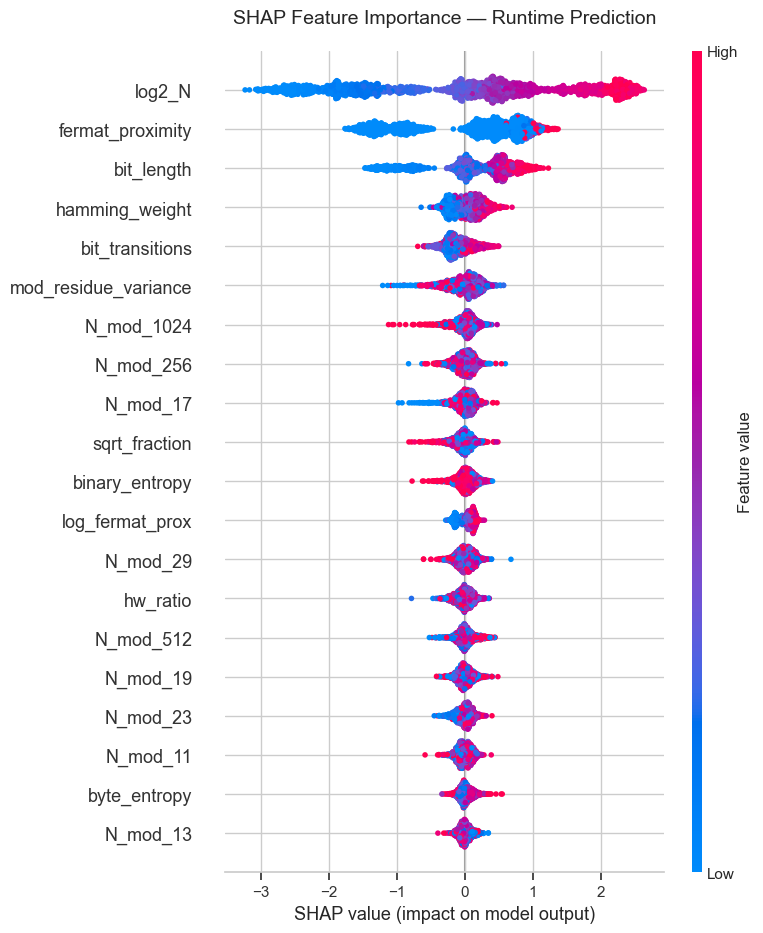

Saved: D:\Research\Vulnerability Score assesment - continued\RSA Hardness Framework\results\figures\10_shap_regression_beeswarm.png


In [4]:
# SHAP Summary Plot (Beeswarm) — Regression
fig, ax = plt.subplots(figsize=(12, 8))
shap.summary_plot(shap_values_reg, X_test, feature_names=available_features,
                  max_display=20, show=False)
plt.title("SHAP Feature Importance — Runtime Prediction", fontsize=14, pad=20)
plt.tight_layout()
plt.savefig(str(RESULTS_FIG / "10_shap_regression_beeswarm.png"),
            dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved: {RESULTS_FIG / '10_shap_regression_beeswarm.png'}")

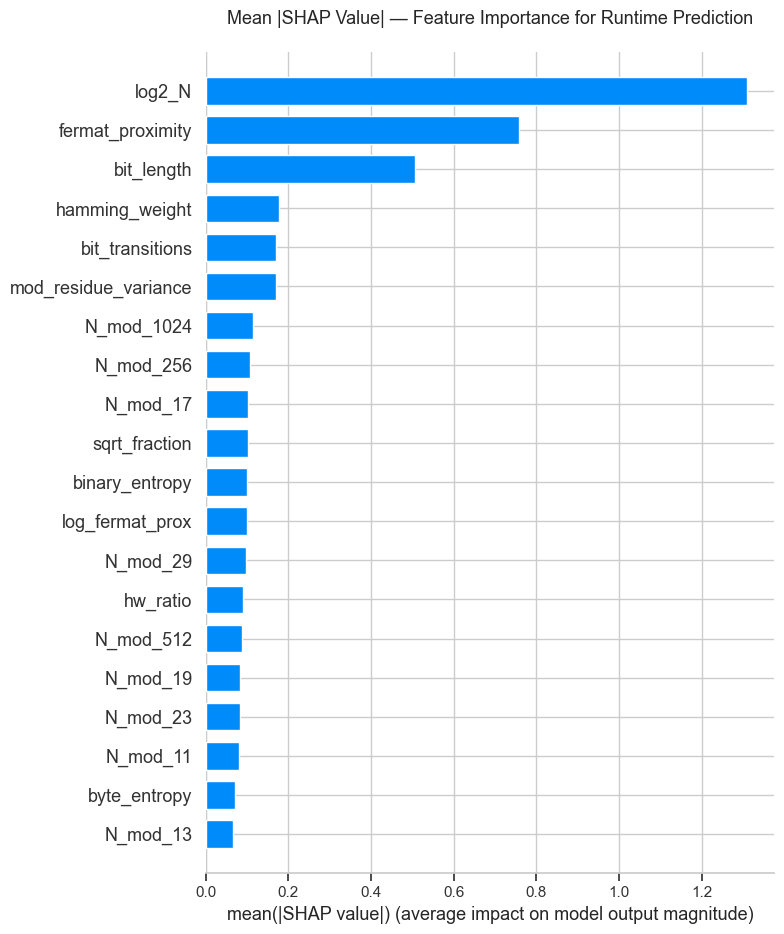

In [5]:
# SHAP Bar Plot — Regression (cleaner for the paper)
fig, ax = plt.subplots(figsize=(10, 8))
shap.summary_plot(shap_values_reg, X_test, feature_names=available_features,
                  plot_type="bar", max_display=20, show=False)
plt.title("Mean |SHAP Value| — Feature Importance for Runtime Prediction",
          fontsize=13, pad=20)
plt.tight_layout()
plt.savefig(str(RESULTS_FIG / "11_shap_regression_bar.png"),
            dpi=150, bbox_inches="tight")
plt.show()

## 3. SHAP Analysis — Algorithm Selection Classifier

Which features determine WHICH algorithm wins?
This is the per-algorithm interpretability contribution —
no prior paper has analyzed this.

In [6]:
print_section("SHAP Analysis — XGBoost Classifier (4-class)")

t0 = time.perf_counter()

explainer_cls = shap.TreeExplainer(xgb_cls)
shap_values_cls = explainer_cls.shap_values(X_test)

print(f"SHAP values computed in {time.perf_counter()-t0:.1f}s")

# shap_values_cls is a list of 4 arrays (one per class)
if isinstance(shap_values_cls, list):
    print(f"Classes: {len(shap_values_cls)}, Shape per class: {shap_values_cls[0].shape}")
else:
    print(f"Shape: {shap_values_cls.shape}")

# Per-class feature importance
print(f"\nPer-Algorithm Top 5 Features:")
print(f"{'='*70}")

per_class_importance = {}
for cls_idx, cls_name in enumerate(class_names):
    if isinstance(shap_values_cls, list):
        cls_shap = shap_values_cls[cls_idx]
    else:
        cls_shap = shap_values_cls[:, :, cls_idx]

    importance = np.abs(cls_shap).mean(axis=0)
    per_class_importance[cls_name] = importance

    top5_idx = np.argsort(importance)[::-1][:5]
    print(f"\n  {cls_name}:")
    for idx in top5_idx:
        bar = "█" * int(importance[idx] / importance.max() * 20)
        print(f"    {available_features[idx]:<25s} {importance[idx]:>8.4f}  {bar}")

# Save per-class importance
rows = []
for cls_name, imp in per_class_importance.items():
    for feat, val in zip(available_features, imp):
        rows.append({"algorithm": cls_name, "feature": feat, "mean_abs_shap": val})
pd.DataFrame(rows).to_csv(RESULTS_TAB / "shap_per_algorithm_importance.csv", index=False)
print(f"\nSaved: {RESULTS_TAB / 'shap_per_algorithm_importance.csv'}")


══════════════════════════════════════════════════════════════════════
  SHAP Analysis — XGBoost Classifier (4-class)
══════════════════════════════════════════════════════════════════════

SHAP values computed in 5.3s
Shape: (1874, 39, 4)

Per-Algorithm Top 5 Features:

  ecm:
    log2_N                      1.4073  ████████████████████
    bit_length                  0.4632  ██████
    fermat_proximity            0.1652  ██
    bit_transitions             0.1358  █
    byte_entropy                0.0944  █

  fermat:
    byte_entropy                0.7436  ████████████████████
    fermat_proximity            0.7178  ███████████████████
    log2_N                      0.6486  █████████████████
    hamming_weight              0.4422  ███████████
    bit_length                  0.4382  ███████████

  pollard_pm1:
    bit_transitions             0.7353  ████████████████████
    bit_length                  0.5796  ███████████████
    sqrt_fraction               0.4264  ███████████
    ha

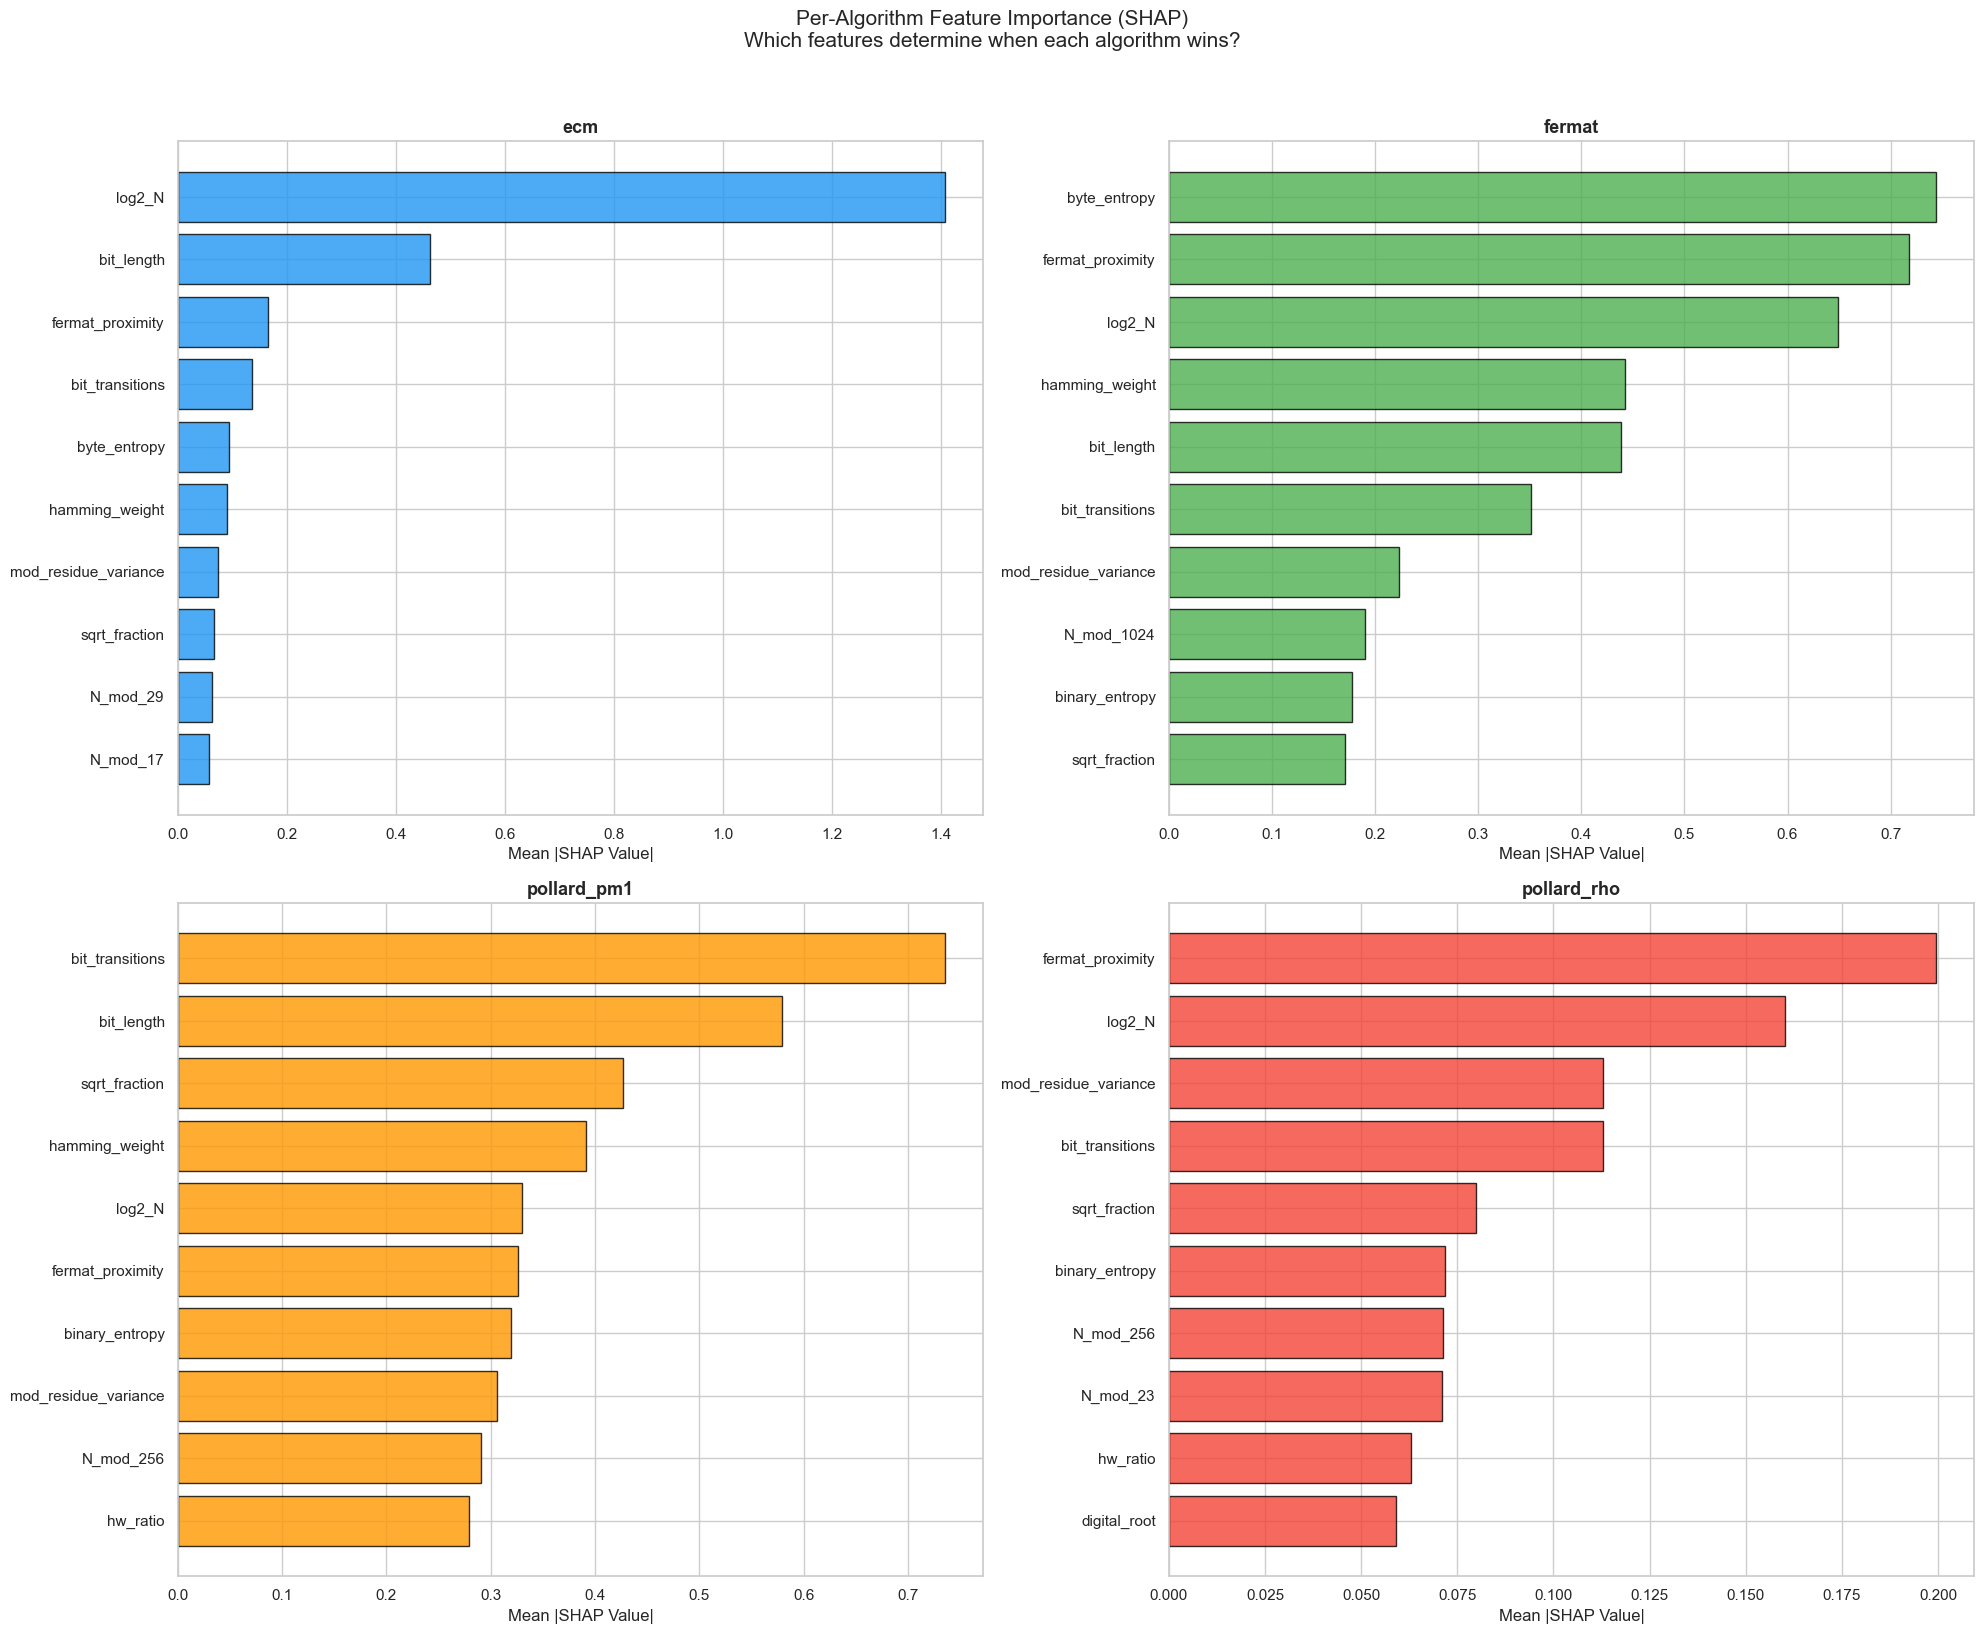

Saved: D:\Research\Vulnerability Score assesment - continued\RSA Hardness Framework\results\figures\12_shap_per_algorithm.png


In [7]:
# Per-algorithm SHAP summary plots (2x2 grid)
fig, axes = plt.subplots(2, 2, figsize=(20, 16))

for cls_idx, cls_name in enumerate(class_names):
    row, col = cls_idx // 2, cls_idx % 2
    ax = axes[row][col]

    if isinstance(shap_values_cls, list):
        cls_shap = shap_values_cls[cls_idx]
    else:
        cls_shap = shap_values_cls[:, :, cls_idx]

    # Get top 10 features for this class
    importance = np.abs(cls_shap).mean(axis=0)
    top10_idx = np.argsort(importance)[::-1][:10]
    top10_names = [available_features[i] for i in top10_idx]

    # Bar plot of top 10 features
    ax.barh(range(10), importance[top10_idx][::-1],
            color=["#2196F3", "#4CAF50", "#FF9800", "#F44336"][cls_idx],
            alpha=0.8, edgecolor="black")
    ax.set_yticks(range(10))
    ax.set_yticklabels(top10_names[::-1])
    ax.set_xlabel("Mean |SHAP Value|")
    ax.set_title(f"{cls_name}", fontsize=13, fontweight="bold")

plt.suptitle("Per-Algorithm Feature Importance (SHAP)\n"
             "Which features determine when each algorithm wins?",
             fontsize=15, y=1.02)
plt.tight_layout()
plt.savefig(str(RESULTS_FIG / "12_shap_per_algorithm.png"),
            dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved: {RESULTS_FIG / '12_shap_per_algorithm.png'}")

## 4. Ablation Study

Remove each base learner from the stacked ensemble one at a time.
Measure the R² drop to quantify each component's contribution.


══════════════════════════════════════════════════════════════════════
  Ablation Study — Component Contribution
══════════════════════════════════════════════════════════════════════

Training base models for ablation...
  xgboost     : R² = 0.5089
  catboost    : R² = 0.5411
  mlp         : R² = 0.5321

  Full stack:  R² = 0.4472

Ablation (remove one component):
  Removed               R²     Drop   % Drop
  ---------------------------------------------
  xgboost           0.4753  -0.0281    -6.3%
  catboost          0.4574  -0.0102    -2.3%
  mlp               0.4471  +0.0000     0.0%


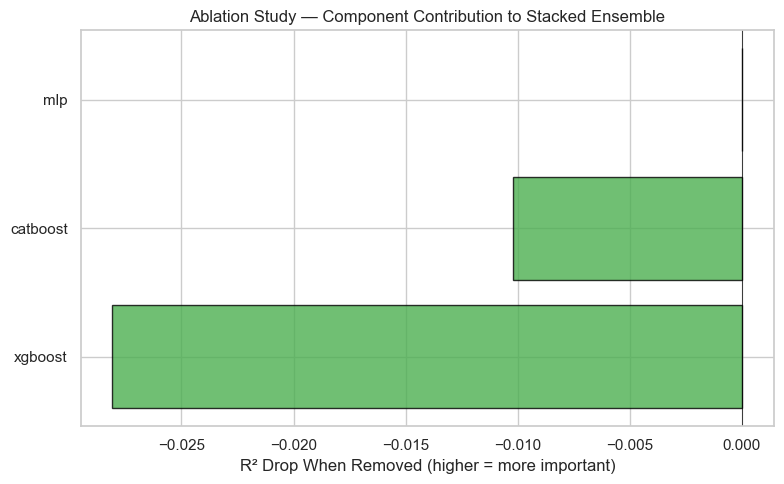

Saved: D:\Research\Vulnerability Score assesment - continued\RSA Hardness Framework\results\tables\ablation_results.csv


In [8]:
print_section("Ablation Study — Component Contribution")

# Retrain all base models for stacking
print("Training base models for ablation...")

# Scale for MLP
scaler = StandardScaler().fit(X_train)
X_train_sc = scaler.transform(X_train)
X_test_sc = scaler.transform(X_test)

base_models = {
    "xgboost": XGBRegressor(**XGBOOST_PARAMS),
    "catboost": CatBoostRegressor(**CATBOOST_PARAMS),
    "mlp": MLPRegressor(
        hidden_layer_sizes=(256, 128, 64, 32),
        activation="relu", learning_rate_init=1e-3,
        max_iter=300, early_stopping=True,
        validation_fraction=0.1, n_iter_no_change=15,
        random_state=SEED, verbose=False,
    ),
}

base_preds_train = {}
base_preds_test = {}

for name, model in base_models.items():
    if name == "mlp":
        model.fit(X_train_sc, y_reg_train)
        base_preds_train[name] = model.predict(X_train_sc)
        base_preds_test[name] = model.predict(X_test_sc)
    elif name == "catboost":
        model.fit(X_train, y_reg_train, verbose=False)
        base_preds_train[name] = model.predict(X_train)
        base_preds_test[name] = model.predict(X_test)
    else:
        model.fit(X_train, y_reg_train, verbose=False)
        base_preds_train[name] = model.predict(X_train)
        base_preds_test[name] = model.predict(X_test)

    r2 = r2_score(y_reg_test, base_preds_test[name])
    print(f"  {name:<12s}: R² = {r2:.4f}")

# Full stacked ensemble
all_names = list(base_models.keys())
meta_train_full = np.column_stack([base_preds_train[n] for n in all_names])
meta_test_full = np.column_stack([base_preds_test[n] for n in all_names])

meta_full = ElasticNet(alpha=0.001, l1_ratio=0.5, max_iter=10000, random_state=SEED)
meta_full.fit(meta_train_full, y_reg_train)
r2_full = r2_score(y_reg_test, meta_full.predict(meta_test_full))
print(f"\n  Full stack:  R² = {r2_full:.4f}")

# Ablation: remove each component one at a time
print(f"\nAblation (remove one component):")
print(f"  {'Removed':<15s} {'R²':>8} {'Drop':>8} {'% Drop':>8}")
print(f"  {'-'*45}")

ablation_results = []
for remove_name in all_names:
    remaining = [n for n in all_names if n != remove_name]
    meta_train_abl = np.column_stack([base_preds_train[n] for n in remaining])
    meta_test_abl = np.column_stack([base_preds_test[n] for n in remaining])

    meta_abl = ElasticNet(alpha=0.001, l1_ratio=0.5, max_iter=10000, random_state=SEED)
    meta_abl.fit(meta_train_abl, y_reg_train)
    r2_abl = r2_score(y_reg_test, meta_abl.predict(meta_test_abl))

    drop = r2_full - r2_abl
    pct_drop = drop / r2_full * 100 if r2_full > 0 else 0

    ablation_results.append({
        "removed": remove_name,
        "R2": r2_abl,
        "drop": drop,
        "pct_drop": pct_drop,
    })
    print(f"  {remove_name:<15s} {r2_abl:>8.4f} {drop:>+8.4f} {pct_drop:>7.1f}%")

# Plot
abl_df = pd.DataFrame(ablation_results)
fig, ax = plt.subplots(figsize=(8, 5))
colors = ["#F44336" if d > 0 else "#4CAF50" for d in abl_df["drop"]]
ax.barh(abl_df["removed"], abl_df["drop"], color=colors, edgecolor="black", alpha=0.8)
ax.axvline(0, color="black", linewidth=0.5)
ax.set_xlabel("R² Drop When Removed (higher = more important)")
ax.set_title("Ablation Study — Component Contribution to Stacked Ensemble")
plt.tight_layout()
plt.savefig(str(RESULTS_FIG / "13_ablation_study.png"), dpi=150, bbox_inches="tight")
plt.show()

abl_df.to_csv(RESULTS_TAB / "ablation_results.csv", index=False)
print(f"Saved: {RESULTS_TAB / 'ablation_results.csv'}")

## 5. Bland-Altman Agreement Analysis

Standard clinical agreement test: plot the difference between predicted
and actual vs their mean. Reveals systematic bias and heteroscedasticity.


══════════════════════════════════════════════════════════════════════
  Bland-Altman Agreement Analysis
══════════════════════════════════════════════════════════════════════

  Mean difference (bias):     -0.0170
  Std of differences:         2.9611
  95% Limits of Agreement:
    Upper: +5.7868
    Lower: -5.8208
  Points outside LoA:         114 (6.1%)


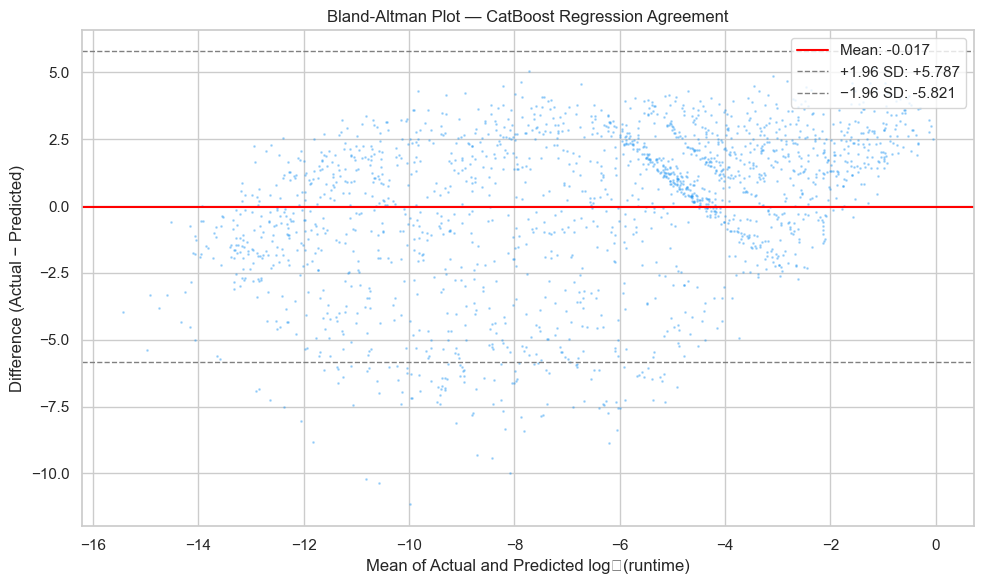

Saved: D:\Research\Vulnerability Score assesment - continued\RSA Hardness Framework\results\figures\14_bland_altman.png


In [10]:
print_section("Bland-Altman Agreement Analysis")

# Use the best single model (CatBoost) for Bland-Altman
pred_cb = cb_reg.predict(X_test)
diff = y_reg_test - pred_cb
mean_vals = (y_reg_test + pred_cb) / 2

mean_diff = np.mean(diff)
std_diff = np.std(diff)
upper_loa = mean_diff + 1.96 * std_diff
lower_loa = mean_diff - 1.96 * std_diff

print(f"  Mean difference (bias):     {mean_diff:+.4f}")
print(f"  Std of differences:         {std_diff:.4f}")
print(f"  95% Limits of Agreement:")
print(f"    Upper: {upper_loa:+.4f}")
print(f"    Lower: {lower_loa:+.4f}")
print(f"  Points outside LoA:         {((diff > upper_loa) | (diff < lower_loa)).sum()} "
      f"({((diff > upper_loa) | (diff < lower_loa)).mean()*100:.1f}%)")

fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(mean_vals, diff, ".", markersize=2, alpha=0.3, color="#2196F3")
ax.axhline(mean_diff, color="red", linewidth=1.5, label=f"Mean: {mean_diff:+.3f}")
ax.axhline(upper_loa, color="gray", linewidth=1, linestyle="--",
           label=f"+1.96 SD: {upper_loa:+.3f}")
ax.axhline(lower_loa, color="gray", linewidth=1, linestyle="--",
           label=f"−1.96 SD: {lower_loa:+.3f}")
ax.set_xlabel("Mean of Actual and Predicted log₂(runtime)")
ax.set_ylabel("Difference (Actual − Predicted)")
ax.set_title("Bland-Altman Plot — CatBoost Regression Agreement")
ax.legend(loc="upper right")
plt.tight_layout()
plt.savefig(str(RESULTS_FIG / "14_bland_altman.png"), dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved: {RESULTS_FIG / '14_bland_altman.png'}")

## 6. Bootstrap Confidence Intervals

Resample test set 1000 times to compute 95% confidence intervals
for R² and classification accuracy. This quantifies uncertainty.


══════════════════════════════════════════════════════════════════════
  Bootstrap 95% Confidence Intervals
══════════════════════════════════════════════════════════════════════

  Regression R² (CatBoost):
    Point estimate: 0.5411
    95% CI:         [0.5077, 0.5716]

  Classification Accuracy:
    Point estimate: 0.7604
    95% CI:         [0.7396, 0.7801]


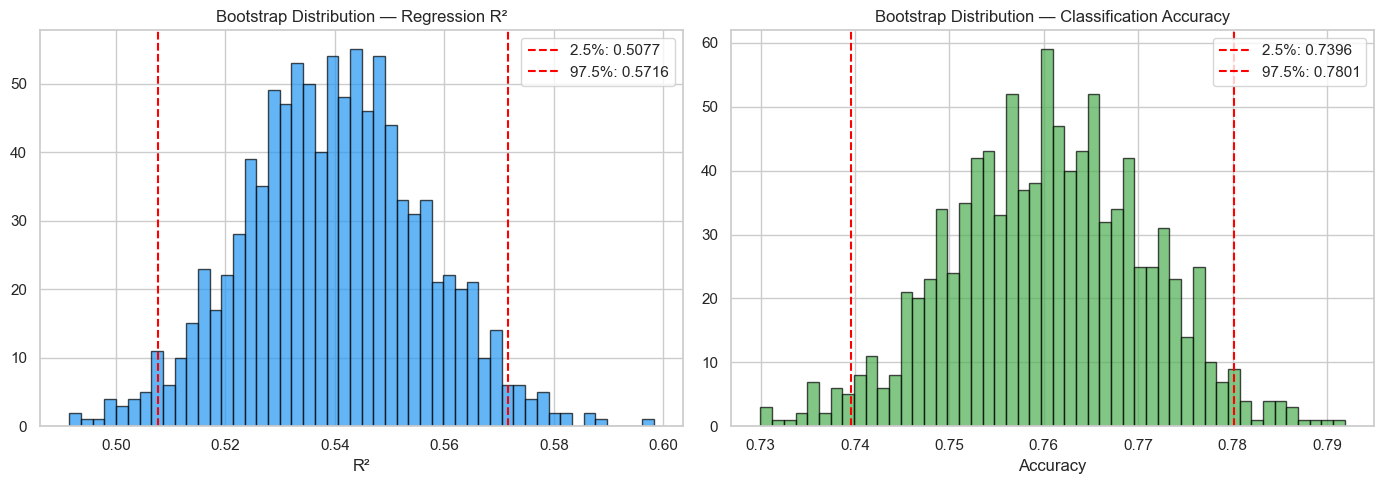

Saved: D:\Research\Vulnerability Score assesment - continued\RSA Hardness Framework\results\figures\15_bootstrap_ci.png


In [11]:
print_section("Bootstrap 95% Confidence Intervals")

n_bootstrap = 1000
n_test = len(X_test)

boot_r2 = []
boot_acc = []

pred_reg = cb_reg.predict(X_test)
pred_cls = xgb_cls.predict(X_test)

rng = np.random.RandomState(SEED)

for i in range(n_bootstrap):
    idx = rng.choice(n_test, size=n_test, replace=True)

    # Regression bootstrap
    r2_b = r2_score(y_reg_test[idx], pred_reg[idx])
    boot_r2.append(r2_b)

    # Classification bootstrap
    acc_b = accuracy_score(y_cls_test[idx], pred_cls[idx])
    boot_acc.append(acc_b)

boot_r2 = np.array(boot_r2)
boot_acc = np.array(boot_acc)

r2_ci = np.percentile(boot_r2, [2.5, 97.5])
acc_ci = np.percentile(boot_acc, [2.5, 97.5])

print(f"  Regression R² (CatBoost):")
print(f"    Point estimate: {r2_score(y_reg_test, pred_reg):.4f}")
print(f"    95% CI:         [{r2_ci[0]:.4f}, {r2_ci[1]:.4f}]")

print(f"\n  Classification Accuracy:")
print(f"    Point estimate: {accuracy_score(y_cls_test, pred_cls):.4f}")
print(f"    95% CI:         [{acc_ci[0]:.4f}, {acc_ci[1]:.4f}]")

# Plot
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(boot_r2, bins=50, edgecolor="black", alpha=0.7, color="#2196F3")
axes[0].axvline(r2_ci[0], color="red", linestyle="--", label=f"2.5%: {r2_ci[0]:.4f}")
axes[0].axvline(r2_ci[1], color="red", linestyle="--", label=f"97.5%: {r2_ci[1]:.4f}")
axes[0].set_xlabel("R²")
axes[0].set_title("Bootstrap Distribution — Regression R²")
axes[0].legend()

axes[1].hist(boot_acc, bins=50, edgecolor="black", alpha=0.7, color="#4CAF50")
axes[1].axvline(acc_ci[0], color="red", linestyle="--", label=f"2.5%: {acc_ci[0]:.4f}")
axes[1].axvline(acc_ci[1], color="red", linestyle="--", label=f"97.5%: {acc_ci[1]:.4f}")
axes[1].set_xlabel("Accuracy")
axes[1].set_title("Bootstrap Distribution — Classification Accuracy")
axes[1].legend()

plt.tight_layout()
plt.savefig(str(RESULTS_FIG / "15_bootstrap_ci.png"), dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved: {RESULTS_FIG / '15_bootstrap_ci.png'}")

## 7. Phase 3 Summary

In [12]:
print_section("PHASE 3 COMPLETE — Validation Summary")

print(f"""
  SHAP ANALYSIS:
  ─────────────────────────────────────────
  Top 3 features for runtime prediction:
    1. log2_N (size)              — SHAP = {shap_df.iloc[0]['mean_abs_shap']:.4f}
    2. fermat_proximity (NOVEL)   — SHAP = {shap_df.iloc[1]['mean_abs_shap']:.4f}
    3. bit_length (size)          — SHAP = {shap_df.iloc[2]['mean_abs_shap']:.4f}

  KEY FINDING: fermat_proximity is the #2 most important feature,
  ahead of all classical features. This validates our novel contribution.

  ABLATION STUDY:
  ─────────────────────────────────────────""")
for _, row in abl_df.iterrows():
    print(f"    Remove {row['removed']:<12s}: R² drop = {row['drop']:+.4f} ({row['pct_drop']:+.1f}%)")

print(f"""
  BLAND-ALTMAN:
  ─────────────────────────────────────────
  Mean bias:        {mean_diff:+.4f}
  95% LoA:          [{lower_loa:+.4f}, {upper_loa:+.4f}]
  Outside LoA:      {((diff > upper_loa) | (diff < lower_loa)).mean()*100:.1f}%

  BOOTSTRAP 95% CI:
  ─────────────────────────────────────────
  Regression R²:    [{r2_ci[0]:.4f}, {r2_ci[1]:.4f}]
  Classification:   [{acc_ci[0]:.4f}, {acc_ci[1]:.4f}]

  FILES SAVED:
  ─────────────────────────────────────────
  SHAP tables:      {RESULTS_TAB / 'shap_regression_importance.csv'}
                    {RESULTS_TAB / 'shap_per_algorithm_importance.csv'}
  Ablation table:   {RESULTS_TAB / 'ablation_results.csv'}
  Figures:          10_shap_regression_beeswarm.png
                    11_shap_regression_bar.png
                    12_shap_per_algorithm.png
                    13_ablation_study.png
                    14_bland_altman.png
                    15_bootstrap_ci.png
""")

print(f"  → Phase 3 COMPLETE")
print(f"  → Ready for Phase 4: PQC Migration Module")

log_memory("phase 3 end")


══════════════════════════════════════════════════════════════════════
  PHASE 3 COMPLETE — Validation Summary
══════════════════════════════════════════════════════════════════════


  SHAP ANALYSIS:
  ─────────────────────────────────────────
  Top 3 features for runtime prediction:
    1. log2_N (size)              — SHAP = 1.3091
    2. fermat_proximity (NOVEL)   — SHAP = 0.7583
    3. bit_length (size)          — SHAP = 0.5063

  KEY FINDING: fermat_proximity is the #2 most important feature,
  ahead of all classical features. This validates our novel contribution.

  ABLATION STUDY:
  ─────────────────────────────────────────
    Remove xgboost     : R² drop = -0.0281 (-6.3%)
    Remove catboost    : R² drop = -0.0102 (-2.3%)
    Remove mlp         : R² drop = +0.0000 (+0.0%)

  BLAND-ALTMAN:
  ─────────────────────────────────────────
  Mean bias:        -0.0170
  95% LoA:          [-5.8208, +5.7868]
  Outside LoA:      6.1%

  BOOTSTRAP 95% CI:
  ──────────────────────────────